In [1]:
from sklearn.datasets import make_regression
import numpy as np 



In [2]:
x,y = make_regression(n_samples=4,n_features=1,n_informative=1,n_targets=1,noise=80,random_state=13)

Bad value in file WindowsPath('C:/Users/bhard/anaconda3/Lib/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle'), line 162 ('mathtext.default: normal  # The default font to use for math.'): Key mathtext.default: 'normal' is not a valid value for mathtext.default; supported values are ['rm', 'cal', 'bfit', 'it', 'tt', 'sf', 'bf', 'default', 'bb', 'frak', 'scr', 'regular']

Bad key axes3d.depthshade in file C:\Users\bhard\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 225 ('axes3d.depthshade   : False   # depth shade for 3D scatter plots')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.10.0/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution

Bad key axes3d.depthshade_minalpha in file C:\Users\bhard\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 226 ('axes3d.depthshade_minalpha : 0.3  # minimum alpha value for depth shading')


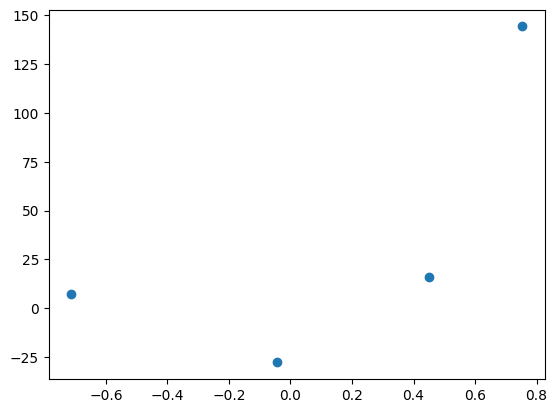

In [3]:
import matplotlib.pyplot as plt 
plt.scatter(x,y)

In [4]:
# lets apply OLS (ordinary least sum)
from sklearn.linear_model import LinearRegression

In [5]:
reg = LinearRegression()
reg.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [6]:
# slope (m)
reg.coef_

array([78.35063668])

In [7]:
# b
reg.intercept_

np.float64(26.15963284313262)

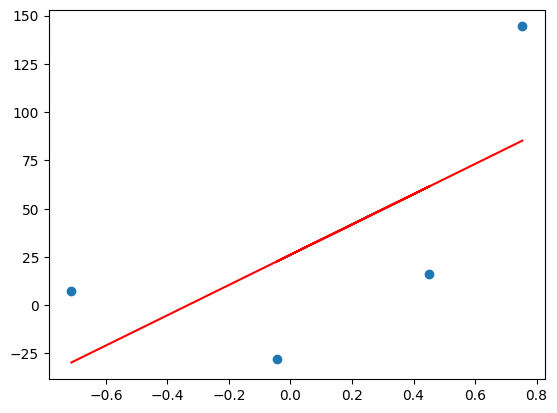

In [8]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color='red')

In [9]:
# lets apply gradiant decent assuming slope is constant m = 78.35
# and lets assume the starting vvalue for intercept b = 0 
y_pred =((78.35*x)+0).reshape(4)

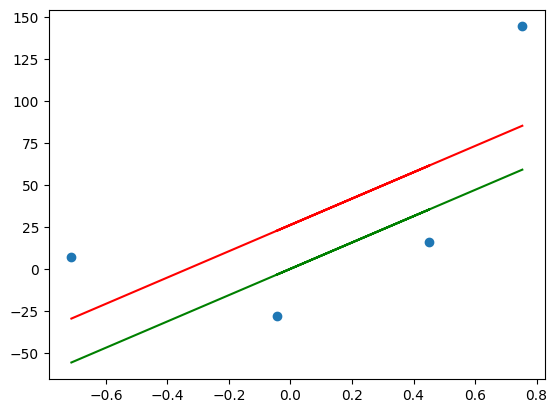

In [10]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color='red',label = 'OLS')
plt.plot(x,y_pred,color='green',label='b=0')

In [11]:
m = 78.35
b=0
loss_slope = -2*np.sum(y-m*x.ravel()-b)
loss_slope

np.float64(-209.27763408209216)

In [12]:
# lets take learning rate = 0.1 
lr = 0.1
step_size = loss_slope*lr
step_size

np.float64(-20.927763408209216)

In [13]:
# calculating new b (intercept)
b = b-step_size
b

np.float64(20.927763408209216)

In [14]:
y_pred1 = ((78.35*x)+b).reshape(4)

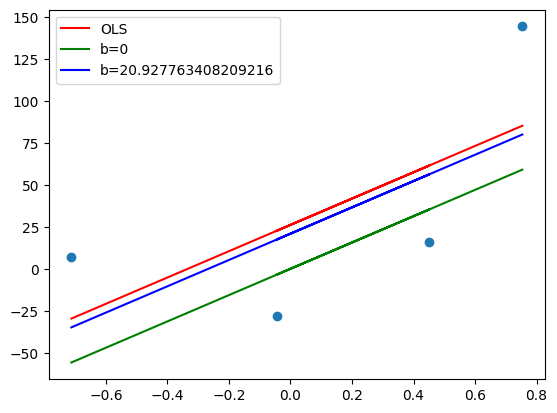

In [15]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color='red',label = 'OLS')
plt.plot(x,y_pred,color='green',label='b=0')
plt.plot(x,y_pred1,color='blue',label=f'b={b}')
plt.legend()
plt.show()

In [16]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt 
import numpy as np 

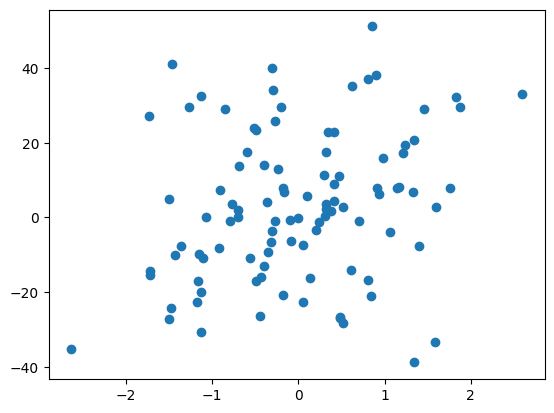

In [17]:
x,y = make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20)
plt.scatter(x,y)

In [18]:
from sklearn.linear_model import LinearRegression

In [19]:
lr = LinearRegression()
lr.fit(x,y)
print(lr.coef_)
print(lr.intercept_)

[4.89945952]
3.0678133887031995


In [20]:
m=83.91
class mygd:
    def __init__(self,learning_rate,epochs):
         self.m = 83.91
         self.b = -120
         self.lr=learning_rate
         self.epochs = epochs

    def fit(self,x,y):
        # calculate the b using gd
        for i in range(self.epochs):
            loss_slope = -2 *np.sum(y-self.m*x.ravel()-self.b)
            self.b = self.b -(self.lr*loss_slope)
            print(loss_slope,self.b)
        print(self.b)
            

In [21]:
gd = mygd(0.001,100)

In [22]:
gd.fit(x,y)

-24852.58003032291 -95.14741996967709
-19882.064024258332 -75.26535594541875
-15905.651219406662 -59.35970472601208
-12724.520975525329 -46.63518375048675
-10179.616780420265 -36.455566970066485
-8143.693424336211 -28.311873545730272
-6514.954739468966 -21.796918806261306
-5211.963791575174 -16.58495501468613
-4169.571033260138 -12.415383981425993
-3335.6568266081113 -9.079727154817881
-2668.525461286489 -6.4112016935313925
-2134.8203690291916 -4.276381324502201
-1707.856295223353 -2.568525029278848
-1366.2850361786818 -1.2022399931001662
-1093.0280289429459 -0.10921196415722023
-874.4224231543575 0.7652104589971372
-699.5379385234859 1.4647483975206232
-559.6303508187881 2.0243787483394113
-447.7042806550302 2.4720830289944415
-358.16342452402444 2.830246453518466
-286.53073961921933 3.1167771931376853
-229.22459169537595 3.3460017848330614
-183.37967335630069 3.529381458189362
-146.70373868504046 3.676085196874402
-117.36299094803303 3.793448187822435
-93.8903927584258 3.887338580580

# finding m and b both in single loop

In [23]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt 
import numpy as np 


In [24]:
x,y = make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20,random_state=13)

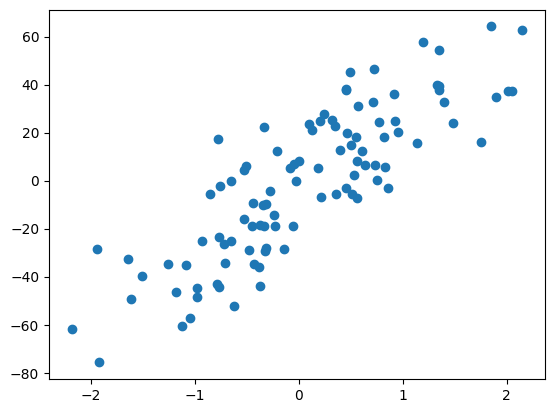

In [25]:
plt.scatter(x,y)

In [26]:
from sklearn.linear_model import LinearRegression

In [27]:
lr = LinearRegression()
lr.fit(x,y)
print(lr.coef_)
print(lr.intercept_)

[27.82809103]
-2.29474455867698


In [28]:
from sklearn.model_selection import cross_val_score

In [29]:
np.mean(cross_val_score(lr,x,y,scoring='r2',cv=10))

np.float64(0.6375011587464419)

In [35]:
class gdreg:
    def __init__(self,learning_rate,epochs):
         self.m = 100
         self.b = -120
         self.lr=learning_rate
         self.epochs = epochs

    def fit(self,x,y):
        # calculate the b using gd
        for i in range(self.epochs):
            loss_slope_b = -2 *np.sum(y-self.m*x.ravel()-self.b)
            loss_slope_m = -2 *np.sum((y-self.m*x.ravel()-self.b)*x.ravel())
            self.m = self.m - (self.lr*loss_slope_m)
            self.b = self.b -(self.lr*loss_slope_b)
        print(self.m)   
        print(self.b)
    def predict(self,x):
        return self.m * x + self.b

In [47]:
gdd = gdreg(0.001,55)

In [48]:
gdd.fit(x_train,y_train)

28.186675739320673
-2.724086009468031


In [49]:
from sklearn.metrics import r2_score

In [50]:
from sklearn.model_selection import train_test_split

In [51]:
x_train,x_test ,y_train,y_test = train_test_split(x,y,test_size=20,random_state=42)

In [52]:
y_pred = gdd.predict(x_test)

In [53]:
r2_score(y_test,y_pred)

0.6185748249572081